In [18]:
from statsmodels.tsa.stattools import grangercausalitytests
from pathlib import Path
import pickle
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

In [ ]:
pkl_path = Path("data\processed_data\combined_latest_snapshot_20251215.pkl")

with open(pkl_path, "rb") as f:
    data = pickle.load(f)
    
sorted_data = sorted(data, key=lambda x: x["date"])

In [ ]:
sic_ts = []
env_ts = {var: [] for var in sorted_data[0]["env"].keys()}

valid_dates = []

for item in sorted_data:
    if item["sic_image"] is None:
        continue

    if any(item["env"][var] is None for var in env_ts):
        continue

    sic_ts.append(np.nanmean(item["sic_image"]))
    for var in env_ts:
        env_ts[var].append(np.nanmean(item["env"][var]))

    valid_dates.append(item["date"])


In [21]:
df = pd.DataFrame({
    "sic": sic_ts,
    "t2m": env_ts["t2m"],
    "u10": env_ts["u10"],
    "v10": env_ts["v10"],
    "msl": env_ts["msl"],
    "sst": env_ts["sst"],
    "tp": env_ts["tp"],
    "mwd": env_ts["mwd"],
    "mwp": env_ts["mwp"],
    "swh": env_ts["swh"],
})

df


,sic,t2m,u10,v10,msl,sst,tp,mwd,mwp,swh
0,1309.177925,275.814362,-1.018117,-0.699863,101314.648438,276.932465,0.001659,126.086533,5.750659,1.597137
1,1309.856144,275.597595,-1.013058,-0.606979,101222.625000,276.868439,0.002078,123.354416,6.152999,1.748621
2,1310.351151,275.363037,-0.881056,-0.706904,101088.281250,276.805023,0.002195,126.887657,6.320333,1.827291
3,1310.664944,275.147369,-0.383653,-0.524499,100850.359375,276.764313,0.002293,152.256744,6.361864,1.712357
4,1311.371035,274.930389,-0.281219,-0.475573,100686.031250,276.691406,0.002474,171.976944,6.167821,1.613757
...,...,...,...,...,...,...,...,...,...,...
74,1368.899172,256.491028,0.245476,-0.120106,101356.523438,273.813568,0.001582,195.702667,7.239691,2.749098
75,1371.304423,257.038483,-0.146681,-0.229095,101244.382812,273.798645,0.001581,179.692719,7.412097,2.745692
76,1372.544261,257.394135,-0.526782,-0.539632,101321.406250,273.783661,0.001519,163.195114,7.173809,2.410198
77,1374.011513,257.677826,-0.593854,-0.542891,101239.820312,273.743591,0.000651,138.856125,7.234806,2.347200


In [22]:
print(df.columns.tolist())

['sic', 't2m', 'u10', 'v10', 'msl', 'sst', 'tp', 'mwd', 'mwp', 'swh']


In [ ]:
def run_linear_granger(df, target="sic", maxlag=5, alpha=0.05):
    results = {}

    env_vars = [c for c in df.columns if c not in [target, "date"]]

    for var in env_vars:
        print("Testing for ", var)
        test_res = grangercausalitytests(
            df[[target, var]],
            maxlag=maxlag,
            verbose=False
        )

        pvals = []
        stats = []

        for lag, res in test_res.items():
            F, p, _, _ = res[0]["ssr_ftest"]
            pvals.append((lag, p))
            stats.append((lag, F))
            print(f"Lag {lag}: F = {F:.3f}, p = {p:.4f}")

        causal_lags = [lag for lag, p in pvals if p < alpha]

        best_lag, min_p = min(pvals, key=lambda x: x[1])

        results[var] = {
            "causal_lags": causal_lags,
            "min_p_value": min_p,
            "best_lag": best_lag,
            "n_samples": len(df) - best_lag,
            "F_at_best_lag": dict(stats)[best_lag]
        }

    return results

In [27]:
results = run_linear_granger(df, target="sic", maxlag=5)

print("\n" + "="*60)
print("LINEAR CAUSALITY SUMMARY (ENV → SIC)")
print("="*60)

for var, r in results.items():
    status = "YES" if len(r["causal_lags"]) > 0 else "NO"
    print(
        f"{var:5s} | causal: {status} | "
        f"min p={r['min_p_value']:.4f} | "
        f"best lag={r['best_lag']} | "
        f"N={r['n_samples']}"
    )


Testing for  t2m
Lag 1: F = 0.002, p = 0.9616
Lag 2: F = 0.200, p = 0.8190
Lag 3: F = 0.230, p = 0.8751
Lag 4: F = 0.179, p = 0.9484
Lag 5: F = 0.607, p = 0.6951
Testing for  u10
Lag 1: F = 2.602, p = 0.1110
Lag 2: F = 1.555, p = 0.2181
Lag 3: F = 1.262, p = 0.2943
Lag 4: F = 1.016, p = 0.4057
Lag 5: F = 1.305, p = 0.2733
Testing for  v10
Lag 1: F = 3.014, p = 0.0867
Lag 2: F = 1.092, p = 0.3411
Lag 3: F = 0.779, p = 0.5099
Lag 4: F = 0.632, p = 0.6415
Lag 5: F = 1.149, p = 0.3445
Testing for  msl
Lag 1: F = 0.687, p = 0.4098
Lag 2: F = 0.270, p = 0.7640
Lag 3: F = 0.318, p = 0.8125
Lag 4: F = 1.001, p = 0.4135
Lag 5: F = 0.799, p = 0.5545
Testing for  sst
Lag 1: F = 3.657, p = 0.0597
Lag 2: F = 1.845, p = 0.1654
Lag 3: F = 1.396, p = 0.2515
Lag 4: F = 0.995, p = 0.4165
Lag 5: F = 1.030, p = 0.4077
Testing for  tp
Lag 1: F = 6.436, p = 0.0133
Lag 2: F = 3.532, p = 0.0344
Lag 3: F = 2.461, p = 0.0699
Lag 4: F = 2.003, p = 0.1043
Lag 5: F = 1.680, p = 0.1524
Testing for  mwd
Lag 1: F = 4

c:\Users\Geovanka\AppData\Local\Programs\Python\Python39\lib\site-packages\statsmodels\tsa\stattools.py:1556: FutureWarning: verbose is deprecated since functions should not print results
  warnings.warn(
c:\Users\Geovanka\AppData\Local\Programs\Python\Python39\lib\site-packages\statsmodels\tsa\stattools.py:1556: FutureWarning: verbose is deprecated since functions should not print results
  warnings.warn(
c:\Users\Geovanka\AppData\Local\Programs\Python\Python39\lib\site-packages\statsmodels\tsa\stattools.py:1556: FutureWarning: verbose is deprecated since functions should not print results
  warnings.warn(
c:\Users\Geovanka\AppData\Local\Programs\Python\Python39\lib\site-packages\statsmodels\tsa\stattools.py:1556: FutureWarning: verbose is deprecated since functions should not print results
  warnings.warn(
c:\Users\Geovanka\AppData\Local\Programs\Python\Python39\lib\site-packages\statsmodels\tsa\stattools.py:1556: FutureWarning: verbose is deprecated since functions should not print 

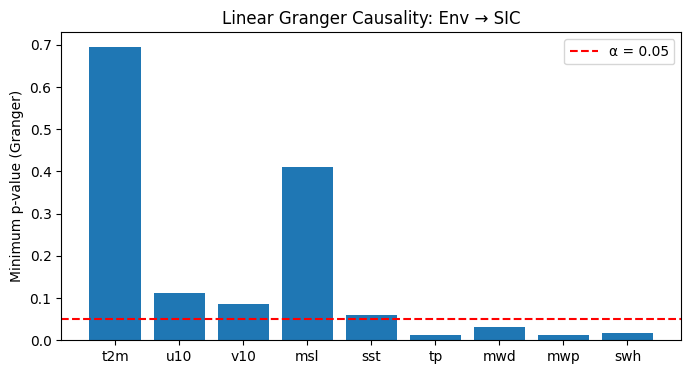

In [29]:
vars_ = list(results.keys())
pvals = [results[v]["min_p_value"] for v in vars_]

plt.figure(figsize=(8, 4))
plt.bar(vars_, pvals)
plt.axhline(0.05, color="red", linestyle="--", label="α = 0.05")
plt.ylabel("Minimum p-value (Granger)")
plt.title("Linear Granger Causality: Env → SIC")
plt.legend()
plt.show()
